# Lab 03: Developing a Tiny Transformer Language Model

### Import libraries


In [1]:
import math, json, os, time, random, csv
import urllib.request
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(42)
random.seed(42)
print("Using device:", device)

Using device: cuda


### Task 1: Load and explore the dataset


In [2]:
N_TRAIN, N_VAL = 3000, 300
BASE = "https://huggingface.co/datasets/roneneldan/TinyStories/resolve/main/"

def fetch_text(filename, n_bytes, cache_file):
    """Download only the first n_bytes of a file from Hugging Face (cached locally)."""
    if not os.path.exists(cache_file):
        req = urllib.request.Request(BASE + filename,
                                     headers={"Range": f"bytes=0-{n_bytes}", "User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(req, timeout=120) as r:
            data = r.read(n_bytes).decode("utf-8", errors="ignore")
        with open(cache_file, "w", encoding="utf-8") as f:
            f.write(data)
    with open(cache_file, encoding="utf-8") as f:
        return f.read()

def split_stories(raw):
    parts = raw.split("<|endoftext|>")[:-1]          # last piece may be cut off, so drop it
    return [s.strip() for s in parts if len(s.strip()) > 50]

train_stories = split_stories(fetch_text("TinyStories-train.txt", 3_000_000, "tinystories_train_sample.txt"))[:N_TRAIN]
val_stories   = split_stories(fetch_text("TinyStories-valid.txt", 500_000,  "tinystories_valid_sample.txt"))[:N_VAL]
print("Train stories:", len(train_stories), "| Validation stories:", len(val_stories))

Train stories: 3000 | Validation stories: 300


In [3]:
for i in range(3):
    print(f"--- Story {i+1} ---")
    print(train_stories[i][:600])
    print()

--- Story 1 ---
One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with it because it was sharp. Lily wanted to share the needle with her mom, so she could sew a button on her shirt.
Lily went to her mom and said, "Mom, I found this needle. Can you share it with me and sew my shirt?" Her mom smiled and said, "Yes, Lily, we can share the needle and fix your shirt."
Together, they shared the needle and sewed the button on Lily's shirt. It was not difficult for them because they were sharing and helping each other. After they finished, Lily thanked her mom for sharing

--- Story 2 ---
Once upon a time, there was a little car named Beep. Beep loved to go fast and play in the sun. Beep was a healthy car because he always had good fuel. Good fuel made Beep happy and strong.
One day, Beep was driving in the park when he saw a big tree. The tree had many leaves that were falling. Beep liked how the leaves fall and wanted to play with them. Beep drov

                mean  median     min     max
characters     864.6     776     253    4107
words          169.5     151      48     837
paragraphs       5.4       5       1      39


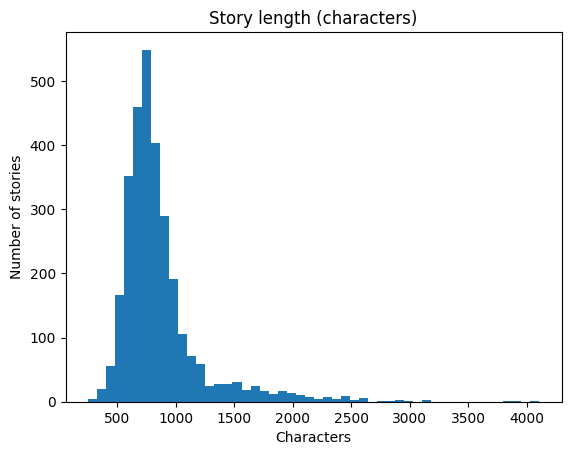

Stories starting with 'Once upon a time': 1786 of 3000


In [4]:
n_chars = np.array([len(s) for s in train_stories])
n_words = np.array([len(s.split()) for s in train_stories])
n_paras = np.array([s.count("\n") + 1 for s in train_stories])

print(f"{'':12s}{'mean':>8s}{'median':>8s}{'min':>8s}{'max':>8s}")
for name, arr in [("characters", n_chars), ("words", n_words), ("paragraphs", n_paras)]:
    print(f"{name:12s}{arr.mean():8.1f}{np.median(arr):8.0f}{arr.min():8d}{arr.max():8d}")

plt.hist(n_chars, bins=50)
plt.title("Story length (characters)")
plt.xlabel("Characters"); plt.ylabel("Number of stories")
plt.show()

starts = sum(s.startswith("Once upon a time") for s in train_stories)
print(f"Stories starting with 'Once upon a time': {starts} of {len(train_stories)}")

### Task 2: Preprocess and tokenize (character level)


In [5]:
def clean_story(s):
    s = (s.replace("\u2019", "'").replace("\u2018", "'")
           .replace("\u201c", '"').replace("\u201d", '"')
           .replace("\u2014", "-").replace("\u2013", "-"))
    return s.encode("ascii", "ignore").decode().strip()

train_text = "\n\n".join(clean_story(s) for s in train_stories)
val_text   = "\n\n".join(clean_story(s) for s in val_stories)
print("Train characters:", len(train_text), "| Validation characters:", len(val_text))

chars = sorted(set(train_text + val_text))
vocab_size = len(chars)
stoi = {c: i for i, c in enumerate(chars)}
itos = {i: c for i, c in enumerate(chars)}

def encode(s):
    return [stoi[c] for c in s if c in stoi]
def decode(ids):
    return "".join(itos[i] for i in ids)

print("Vocabulary size:", vocab_size)
print("Characters:", "".join(chars))
print(encode("Once upon a time"))
print(decode(encode("Once upon a time")))

Train characters: 2599818 | Validation characters: 257248
Vocabulary size: 74
Characters: 
 !"$',-.0123456789:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz
[36, 61, 50, 52, 1, 68, 63, 62, 61, 1, 48, 1, 67, 56, 60, 52]
Once upon a time


### Task 3: Prepare training data


In [6]:
BLOCK_SIZE = 128     # how many characters the model sees at once
BATCH_SIZE = 32

train_data = torch.tensor(encode(train_text), dtype=torch.long)
val_data   = torch.tensor(encode(val_text), dtype=torch.long)

def get_batch(split):
    data = train_data if split == "train" else val_data
    ix = torch.randint(len(data) - BLOCK_SIZE - 1, (BATCH_SIZE,))
    x = torch.stack([data[i:i + BLOCK_SIZE] for i in ix])
    y = torch.stack([data[i + 1:i + BLOCK_SIZE + 1] for i in ix])
    return x.to(device), y.to(device)

xb, yb = get_batch("train")
print("Input shape:", xb.shape, "| Target shape:", yb.shape)
print("INPUT :", repr(decode(xb[0][:40].tolist())))
print("TARGET:", repr(decode(yb[0][:40].tolist())))

Input shape: torch.Size([32, 128]) | Target shape: torch.Size([32, 128])
INPUT : 'ing to see a petal. She talked to the ro'
TARGET: 'ng to see a petal. She talked to the ros'


### Task 4: Build the Transformer architecture


In [7]:
class CausalSelfAttention(nn.Module):
    """Masked multi-head self-attention: each position can only look at earlier positions."""
    def __init__(self, n_embd, n_head, block_size, dropout):
        super().__init__()
        assert n_embd % n_head == 0, "n_embd must be divisible by n_head"
        self.n_head = n_head
        self.qkv = nn.Linear(n_embd, 3 * n_embd)
        self.proj = nn.Linear(n_embd, n_embd)
        self.attn_drop = nn.Dropout(dropout)
        self.resid_drop = nn.Dropout(dropout)
        mask = torch.tril(torch.ones(block_size, block_size)).view(1, 1, block_size, block_size)
        self.register_buffer("mask", mask)

    def forward(self, x):
        B, T, C = x.shape
        q, k, v = self.qkv(x).split(C, dim=2)
        q = q.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        k = k.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        v = v.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        att = (q @ k.transpose(-2, -1)) / math.sqrt(k.size(-1))       # attention scores
        att = att.masked_fill(self.mask[:, :, :T, :T] == 0, float("-inf"))  # causal mask
        att = F.softmax(att, dim=-1)
        att = self.attn_drop(att)
        y = att @ v
        y = y.transpose(1, 2).contiguous().view(B, T, C)
        return self.resid_drop(self.proj(y))

class FeedForward(nn.Module):
    def __init__(self, n_embd, dropout):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.GELU(),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout),
        )
    def forward(self, x):
        return self.net(x)

class Block(nn.Module):
    """One Transformer block: LayerNorm -> attention -> residual, LayerNorm -> feed-forward -> residual."""
    def __init__(self, n_embd, n_head, block_size, dropout):
        super().__init__()
        self.ln1 = nn.LayerNorm(n_embd)
        self.attn = CausalSelfAttention(n_embd, n_head, block_size, dropout)
        self.ln2 = nn.LayerNorm(n_embd)
        self.ffn = FeedForward(n_embd, dropout)
    def forward(self, x):
        x = x + self.attn(self.ln1(x))   # residual connection
        x = x + self.ffn(self.ln2(x))    # residual connection
        return x

class TinyTransformer(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        self.tok_emb = nn.Embedding(cfg["vocab_size"], cfg["n_embd"])    # token embeddings
        self.pos_emb = nn.Embedding(cfg["block_size"], cfg["n_embd"])    # positional embeddings
        self.drop = nn.Dropout(cfg["dropout"])
        self.blocks = nn.Sequential(*[
            Block(cfg["n_embd"], cfg["n_head"], cfg["block_size"], cfg["dropout"])
            for _ in range(cfg["n_layer"])
        ])
        self.ln_f = nn.LayerNorm(cfg["n_embd"])
        self.lm_head = nn.Linear(cfg["n_embd"], cfg["vocab_size"], bias=False)
        self.lm_head.weight = self.tok_emb.weight                        # weight tying
        self.apply(self._init_weights)

    def _init_weights(self, m):
        if isinstance(m, nn.Linear):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)
            if m.bias is not None:
                nn.init.zeros_(m.bias)
        elif isinstance(m, nn.Embedding):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        pos = torch.arange(T, device=idx.device)
        x = self.drop(self.tok_emb(idx) + self.pos_emb(pos))
        x = self.blocks(x)
        x = self.ln_f(x)
        logits = self.lm_head(x)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=1.0, top_k=None):
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.cfg["block_size"]:]
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :] / temperature
            if top_k is not None:
                v, _ = torch.topk(logits, min(top_k, logits.size(-1)))
                logits[logits < v[:, [-1]]] = float("-inf")
            probs = F.softmax(logits, dim=-1)
            next_id = torch.multinomial(probs, num_samples=1)
            idx = torch.cat([idx, next_id], dim=1)
        return idx

print("Model classes defined")

Model classes defined


### Task 5: Initialize the model, loss function and optimizer

In [8]:
config = {
    "vocab_size": vocab_size,
    "block_size": BLOCK_SIZE,
    "n_embd": 128,      # size of each embedding
    "n_head": 4,        # attention heads
    "n_layer": 4,       # Transformer blocks
    "dropout": 0.1,
}

model = TinyTransformer(config).to(device)
n_params = sum(p.numel() for p in model.parameters())
print(f"Parameters: {n_params:,}")

# Loss: cross-entropy (computed inside model.forward). Optimizer: AdamW.
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=0.01)

# Sanity check: before training, loss should be close to ln(vocab_size)
xb, yb = get_batch("train")
_, loss = model(xb, yb)
print("Initial loss:", round(loss.item(), 3), "| ln(vocab_size):", round(math.log(vocab_size), 3))

Parameters: 819,200
Initial loss: 4.371 | ln(vocab_size): 4.304


### Task 6: Train the model


In [9]:
@torch.no_grad()
def estimate_loss(model, eval_iters=40):
    model.eval()
    out = {}
    for split in ["train", "val"]:
        losses = torch.zeros(eval_iters)
        for k in range(eval_iters):
            xb, yb = get_batch(split)
            _, loss = model(xb, yb)
            losses[k] = loss.item()
        out[split] = losses.mean().item()
    model.train()
    return out

def train_model(cfg, epochs=8, steps_per_epoch=100, lr=1e-3):
    torch.manual_seed(42)
    m = TinyTransformer(cfg).to(device)
    opt = torch.optim.AdamW(m.parameters(), lr=lr, weight_decay=0.01)
    history = {"epoch": [], "train_loss": [], "val_loss": []}
    start = time.time()
    m.train()
    for epoch in range(1, epochs + 1):
        for step in range(steps_per_epoch):
            xb, yb = get_batch("train")
            logits, loss = m(xb, yb)                                  # forward pass + loss
            opt.zero_grad(set_to_none=True)
            loss.backward()                                           # backpropagation
            torch.nn.utils.clip_grad_norm_(m.parameters(), 1.0)       # gradient clipping
            opt.step()                                                # update parameters
        losses = estimate_loss(m)
        history["epoch"].append(epoch)
        history["train_loss"].append(losses["train"])
        history["val_loss"].append(losses["val"])
        print(f"Epoch {epoch}/{epochs} | train loss {losses['train']:.3f} | val loss {losses['val']:.3f} | {time.time()-start:.0f}s")
    return m, history

EPOCHS = 8
STEPS_PER_EPOCH = 100
model, history = train_model(config, epochs=EPOCHS, steps_per_epoch=STEPS_PER_EPOCH)

Epoch 1/8 | train loss 2.331 | val loss 2.317 | 2s
Epoch 2/8 | train loss 2.241 | val loss 2.227 | 5s
Epoch 3/8 | train loss 2.076 | val loss 2.052 | 7s
Epoch 4/8 | train loss 1.919 | val loss 1.877 | 9s
Epoch 5/8 | train loss 1.768 | val loss 1.731 | 11s
Epoch 6/8 | train loss 1.654 | val loss 1.621 | 13s
Epoch 7/8 | train loss 1.555 | val loss 1.501 | 15s
Epoch 8/8 | train loss 1.472 | val loss 1.421 | 17s


### Task 7: Monitor training (loss curves)

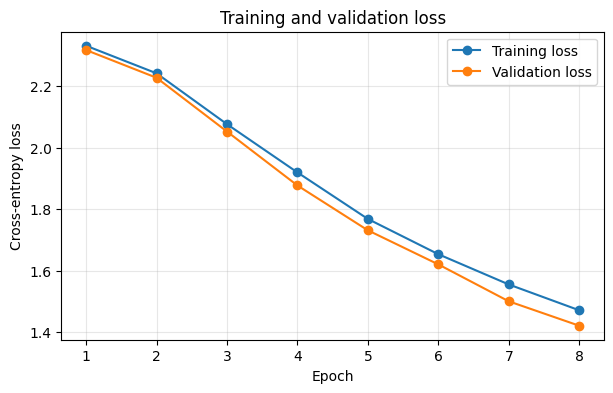

Epoch 1: train loss 2.3309 | val loss 2.3169
Epoch 2: train loss 2.2413 | val loss 2.2269
Epoch 3: train loss 2.0761 | val loss 2.0522
Epoch 4: train loss 1.9194 | val loss 1.8770
Epoch 5: train loss 1.7682 | val loss 1.7313
Epoch 6: train loss 1.6537 | val loss 1.6206
Epoch 7: train loss 1.5555 | val loss 1.5007
Epoch 8: train loss 1.4716 | val loss 1.4215


In [10]:
def plot_history(history, title="Training and validation loss"):
    plt.figure(figsize=(7, 4))
    plt.plot(history["epoch"], history["train_loss"], marker="o", label="Training loss")
    plt.plot(history["epoch"], history["val_loss"], marker="o", label="Validation loss")
    plt.xlabel("Epoch"); plt.ylabel("Cross-entropy loss")
    plt.title(title); plt.legend(); plt.grid(alpha=0.3)
    return plt

os.makedirs("results", exist_ok=True)
plot_history(history).savefig("results/loss_curve.png", dpi=150, bbox_inches="tight")
plt.show()
for e, tl, vl in zip(history["epoch"], history["train_loss"], history["val_loss"]):
    print(f"Epoch {e}: train loss {tl:.4f} | val loss {vl:.4f}")

### Task 8: Evaluate (validation loss and perplexity)


In [11]:
final = estimate_loss(model, eval_iters=100)
val_loss = final["val"]
perplexity = math.exp(val_loss)
print(f"Validation loss : {val_loss:.4f}")
print(f"Perplexity      : {perplexity:.2f}")
print(f"Random guessing would give perplexity = {vocab_size}")

Validation loss : 1.4237
Perplexity      : 4.15
Random guessing would give perplexity = 74


### Task 9: Generate stories

In [12]:
def generate_text(m, prompt="Once upon a time", max_new_tokens=300, temperature=0.8, top_k=20):
    m.eval()
    idx = torch.tensor([encode(prompt)], dtype=torch.long, device=device)
    out = m.generate(idx, max_new_tokens, temperature=temperature, top_k=top_k)
    return decode(out[0].tolist())

torch.manual_seed(1)
print(generate_text(model, "Once upon a time"))

Once upon a time, there day named "You are! So said, are out some of the larke the the cat. He rab dog her and bet was friend and stilly all he will now his oned around but don the poorted in if to he caround. He downe the the the cots and Shelp the they all that it says, "I a a care you said in you. "I her aren yr


In [22]:
# Try different prompts and temperatures
for prompt, temp in [("Once upon a time", 0.5), ("Once upon a time", 1.0), ("One day, a little girl", 0.8), ("Tom and his dog", 0.8)]:
    torch.manual_seed(1)
    print(f" prompt: {prompt!r} | temperature: {temp} ")
    print(generate_text(model, prompt, 250, temperature=temp))
    print()

 prompt: 'Once upon a time' | temperature: 0.5 
Once upon a time, there was a big to play. They was and so saw a boy the lauged the park. They rabbig and said, "I was a can to the it her play and you are looke around but down day the ran and say he care and help the the there. 

Once upon a time, there was a good

 prompt: 'Once upon a time' | temperature: 1.0 
Once upon a time, "You playe, wy Lilly sayss, and sheark. Yes, Lily all back."
They dad but had to playhe was sorter him in a bad stider alp he will now playe what the the nee thing in the rouzzixpatices. Ful's and Saroud and dold.

"Once uponly, I feer was a now it

 prompt: 'One day, a little girl' | temperature: 0.8 
One day, a little girl nots wode. Shey was a bellsso proop around.
Sam for the larked too down. They ran dogeren and said: "What you, "I sid. Molly taked on was a on a around by nee the foom the rounds. They spook oner and says and dold. She and Shelp the they and her and

 prompt: 'Tom and his dog' | temperature

### Task 10: Experiment with model settings


In [23]:
EXP_EPOCHS = 5
experiments = {
    "1 layer, 4 heads":  dict(n_layer=1, n_head=4),
    "2 layers, 4 heads": dict(n_layer=2, n_head=4),
    "4 layers, 1 head":  dict(n_layer=4, n_head=1),
    "4 layers, 4 heads": dict(n_layer=4, n_head=4),
}

rows, histories = [], {}
for name, change in experiments.items():
    print(f"\n {name} ")
    cfg = {**config, **change}
    m, h = train_model(cfg, epochs=EXP_EPOCHS, steps_per_epoch=STEPS_PER_EPOCH)
    histories[name] = h
    vl = estimate_loss(m, eval_iters=100)["val"]
    torch.manual_seed(1)
    sample = generate_text(m, "Once upon a time", 200).replace("\n", " ")
    rows.append({"Setting": name, "Parameters": sum(p.numel() for p in m.parameters()),
                 "Val loss": round(vl, 4), "Perplexity": round(math.exp(vl), 2), "Sample": sample})

with open("results/experiments.csv", "w", newline="", encoding="utf-8") as f:
    w = csv.DictWriter(f, fieldnames=list(rows[0].keys()))
    w.writeheader()
    w.writerows(rows)

print(f"{'Setting':20s}{'Parameters':>12s}{'Val loss':>10s}{'Perplexity':>12s}")
for r in rows:
    print(f"{r['Setting']:20s}{r['Parameters']:>12,}{r['Val loss']:>10.4f}{r['Perplexity']:>12.2f}")


 1 layer, 4 heads 
Epoch 1/5 | train loss 2.319 | val loss 2.314 | 1s
Epoch 2/5 | train loss 2.234 | val loss 2.206 | 2s
Epoch 3/5 | train loss 2.044 | val loss 2.013 | 3s
Epoch 4/5 | train loss 1.915 | val loss 1.877 | 4s
Epoch 5/5 | train loss 1.820 | val loss 1.780 | 4s

 2 layers, 4 heads 
Epoch 1/5 | train loss 2.332 | val loss 2.316 | 1s
Epoch 2/5 | train loss 2.240 | val loss 2.226 | 2s
Epoch 3/5 | train loss 2.047 | val loss 2.019 | 4s
Epoch 4/5 | train loss 1.897 | val loss 1.858 | 5s
Epoch 5/5 | train loss 1.779 | val loss 1.733 | 6s

 4 layers, 1 head 
Epoch 1/5 | train loss 2.334 | val loss 2.318 | 2s
Epoch 2/5 | train loss 2.246 | val loss 2.231 | 4s
Epoch 3/5 | train loss 2.065 | val loss 2.040 | 6s
Epoch 4/5 | train loss 1.855 | val loss 1.814 | 8s
Epoch 5/5 | train loss 1.697 | val loss 1.658 | 10s

 4 layers, 4 heads 
Epoch 1/5 | train loss 2.331 | val loss 2.317 | 2s
Epoch 2/5 | train loss 2.241 | val loss 2.227 | 5s
Epoch 3/5 | train loss 2.076 | val loss 2.052 | 7s

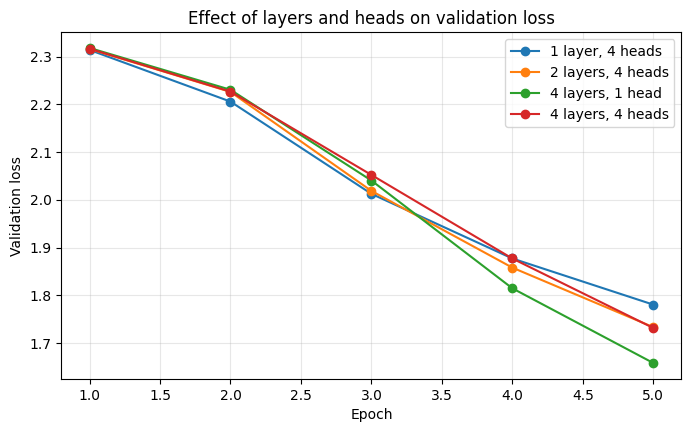

[1 layer, 4 heads] Once upon a times old wodone any toold the sand ooo happed ined the he he arex. "Commbecate hat to play." Soe sarie a it pa and asheided alppy. Timmy whapy lond and they fund a ther the rand fizienthey sponed and doo

[2 layers, 4 heads] Once upon a time, "You ou see," "I slot wers, a hoousard." But the yold bear." They day but heirn findshe wanted tre hit bat to as sid. A the the do newas a ond a rend the ne a ditt ime, she fizirend yout big and a b

[4 layers, 1 head] Once upon a time, "You be specare told the sto prooularke. But the yel he are blay the cat on it bed. He was around and cal and as sid. Mall he will nd and loved are to but den the ping round it weref theg and the bo

[4 layers, 4 heads] Once upon a time, "Yoriom, fe, you slot witss and he arke. But the yot he ard blay the cat on irnd dounde to aroun. The chat to as sided at from. He nowas a ond a reat the neeared a the rand fromend, "He gouldet yout



In [24]:
plt.figure(figsize=(8, 4.5))
for name, h in histories.items():
    plt.plot(h["epoch"], h["val_loss"], marker="o", label=name)
plt.xlabel("Epoch"); plt.ylabel("Validation loss")
plt.title("Effect of layers and heads on validation loss")
plt.legend(); plt.grid(alpha=0.3)
plt.savefig("results/experiments_val_loss.png", dpi=150, bbox_inches="tight")
plt.show()

for r in rows:
    print(f"[{r['Setting']}] {r['Sample']}\n")

In [25]:
# Effect of the number of epochs (uses the main training run from Task 6)
print("Validation loss after 2 epochs:", round(history["val_loss"][1], 4))
print(f"Validation loss after {EPOCHS} epochs:", round(history["val_loss"][-1], 4))

Validation loss after 2 epochs: 2.2269
Validation loss after 8 epochs: 1.4215


### Task 11: Save the trained model


In [26]:
os.makedirs("results/saved_model", exist_ok=True)
torch.save(model.state_dict(), "results/saved_model/tiny_transformer.pt")
with open("results/saved_model/config.json", "w") as f:
    json.dump(config, f)
with open("results/saved_model/vocab.json", "w") as f:
    json.dump(chars, f)
print("Saved to results/saved_model/")

# Test loading it back
with open("results/saved_model/config.json") as f:
    cfg_loaded = json.load(f)
loaded = TinyTransformer(cfg_loaded).to(device)
loaded.load_state_dict(torch.load("results/saved_model/tiny_transformer.pt", map_location=device))
loaded.eval()
torch.manual_seed(1)
print(generate_text(loaded, "Once upon a time", 150))

Saved to results/saved_model/
Once upon a time, there day named "You are! So said, are out some of the larke the the cat. He rab dog her and bet was friend and stilly all he will now his oned arou


### Optional: Chat window with Gradio

In [27]:
import gradio as gr

def story_chat(prompt, length, temperature):
    return generate_text(model, prompt, int(length), temperature=float(temperature))

demo = gr.Interface(
    fn=story_chat,
    inputs=[
        gr.Textbox(label="Start of the story", value="Once upon a time"),
        gr.Slider(50, 500, value=250, step=10, label="Length (characters)"),
        gr.Slider(0.3, 1.5, value=0.8, step=0.1, label="Temperature"),
    ],
    outputs=gr.Textbox(label="Generated story", lines=12),
    title="Tiny Story Generator",
)
demo.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://6a60696f1c22118583.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


### Discussion: what mechanisms improve performance?

- **Token and positional embeddings:** turn characters into vectors and tell the model where each character is, since attention alone ignores order.
- **Masked (causal) self-attention:** lets each position use earlier characters as context while preventing it from seeing the answer (future characters).
- **Multi-head attention:** several heads look at different relationships at the same time (for example nearby letters and earlier words).
- **Feed-forward layers with GELU:** add non-linear processing after attention.
- **Residual connections:** let information and gradients flow through deep stacks, so deeper models train more easily.
- **Layer normalization:** keeps values stable so training is faster and steadier.
- **Dropout and weight decay:** reduce overfitting.
- **AdamW optimizer and gradient clipping:** efficient and stable parameter updates.
- **Weight tying:** shares the embedding and output weights, which reduces parameters.
- **Sampling settings (temperature, top-k):** do not change the model but improve the quality of generated text.
- **Data and training time:** more data, a larger model and more training steps lower the loss further.